In [1]:
from pathlib import Path
import os, sys
_root = next((p for p in [Path.cwd().resolve(), *Path.cwd().resolve().parents] if (p / "REPOSITORY_PROVENANCE.json").is_file()), None)
if _root is None:
    raise RuntimeError("Start Jupyter inside this experiment repository.")
os.chdir(_root)
sys.path.insert(0, str(_root))


# Connected majority IQP and a tuned MLP size study

## Circuit: genuine inter-block connections

Keep 21 qubits, the trainable affine neural encoder $\phi_i(s)=w_i^Ts+b_i$,
the three $R_{ZZ}$ and one $R_{ZZZ}$ gate inside each triple, and global
binary majority over all 21 outcomes. Add the six trainable bridges
$$R_{Z_3Z_4}(\beta_1),\ R_{Z_6Z_7}(\beta_2),\ldots,
R_{Z_{18}Z_{19}}(\beta_6).$$
The full circuit remains $H^{\otimes21}D(s)H^{\otimes21}$ with commuting
diagonal gates in $D$. The graph is connected; there are **139 parameters**:
84 neural feature weights, 21 biases, 21 internal pair angles, seven
three-body angles, and six bridge angles. All are trainable.
The neural biases start at $\pi/2$; interaction and bridge angles independently start from $\mathcal N(0,0.5^2)$.

**Why this is not a product of triples.** Across any former block boundary,
all gates other than its bridge act entirely on one side of the cut and
commute with that bridge. They can therefore be moved after it without
changing Schmidt coefficients. Applied to the initial $|+\rangle$ state,
$$R_{ZZ}(\beta)=\cos(\beta/2)I\otimes I-i\sin(\beta/2)Z\otimes Z$$
gives two orthogonal product components. Thus the reduced-state purity is
$$\operatorname{Tr}\rho_{\rm left}^{2}
=\cos^4(\beta/2)+\sin^4(\beta/2)=1-\tfrac12\sin^2\beta.$$
It is below one unless $\beta$ is an integer multiple of $\pi$; this holds
independently of the encoded state. Initial and trained bridge purities are
reported below. A full 21-qubit state-vector reference also verifies the result.

**Still classically simulable.** The connected chain has bond dimension two
in a matrix-product-state representation (four in the doubled probability
network). Exact count-generating-function contraction and inverse FFT compute
global majority probabilities without factorizing the blocks. Complexity is
polynomial for this chain; connecting blocks is not a classical-hardness proof.
No Fourier truncation or product-state approximation is used.

## Prospective comparison and selection

MLPs have architecture Linear(4,h) → Tanh → Linear(h,2), with softmax actions.
Widths $h\in\{1,2,4,6,9,12,16,19\}$ give 9, 16, 30, 44, 65, 86, 114, 135
parameters. The largest is approximately matched to the connected IQP's 139.
Learning rates 0.003, 0.01, 0.03 and 0.1 are tested on **eight development
seeds per configuration**. The 0.1 rate was added during development, before
any final-test runs. For each width, lock the rate maximizing development AUC.
Also lock the best-AUC and fastest-convergence configurations from development.
The latter is tested additionally if distinct from the width-selected models.

All selected MLP sizes, the fixed connected IQP, and the disconnected control
are evaluated on **20 untouched test seeds**. No test-driven architecture or
learning-rate selection is permitted. Each run uses 500 training episodes,
200 steps maximum, the same corrected full-100-window freezing rule, the same
REINFORCE settings, and 100 independent frozen-policy evaluation episodes.
The IQP learning rate remains 0.03; this study does not search IQP bridge strength.

Primary outcomes: normalized training-return AUC and first episode reaching
a rolling-100 mean ≥195. Runs not reaching the criterion are assigned 501
and retained in the restricted mean. This measures sample efficiency, not
wall-clock efficiency. Paired exact sign-randomization tests receive one Holm
correction across every selected MLP's two primary IQP comparisons.

For saturation, nonsignificance alone is insufficient. Before test, practical
equivalence margins were set to 0.02 AUC and 25 restricted solve episodes.
Width 19 is compared with widths 9, 12 and 16 using conservative 98.3333%
paired-bootstrap intervals; both intervals must lie inside their margins.
Otherwise saturation is **not established**, even if the mean curve looks flat.

The search is finite and task-specific. Parameter counts do not match
expressivity or initialization priors; the IQP had prior architecture selection.
Neither superiority to this grid nor inter-block entanglement demonstrates
quantum advantage. All development scores, test failures and checkpoints remain
available. The paper is unchanged.


In [2]:
from pathlib import Path
import json
from IPython.display import display, Image, Markdown
ROOT=Path.cwd()/'results'/'connected_iqp_mlp_study'
r=json.loads((ROOT/'test_analysis.json').read_text())
print('Development-selected best AUC:',r['selection']['best_auc_mlp'])
print('Development-selected fastest convergence:',r['selection']['best_solve_mlp'])
print('Audited test runs:',r['audited_test_runs'])

Development-selected best AUC: mlp_h04_lr0p1
Development-selected fastest convergence: mlp_h12_lr0p1
Audited test runs: 200


## Held-out size curve and selected comparisons

In [3]:
lines=['| Model | Parameters | LR | AUC | Restricted solve episode | Solved | Held-out return | Initial return |', '|---|---:|---:|---:|---:|---:|---:|---:|']
for name,s in r['summary'].items():
    lines.append(f"| {name} | {s['parameters']} | {s['lr']} | {s['auc']['mean']:.4f} | {s['solve_episode']['mean']:.1f} | {s['solved']}/20 | {s['heldout']['mean']:.2f} | {s['initial_return']:.2f} |")
display(Markdown('\n'.join(lines)))

| Model | Parameters | LR | AUC | Restricted solve episode | Solved | Held-out return | Initial return |
|---|---:|---:|---:|---:|---:|---:|---:|
| mlp_h01_lr0p1 | 9 | 0.1 | 0.7229 | 374.4 | 15/20 | 191.25 | 16.14 |
| mlp_h02_lr0p1 | 16 | 0.1 | 0.7985 | 277.7 | 18/20 | 197.10 | 19.29 |
| mlp_h04_lr0p1 | 30 | 0.1 | 0.8469 | 263.6 | 17/20 | 191.58 | 20.00 |
| mlp_h06_lr0p1 | 44 | 0.1 | 0.8631 | 261.9 | 17/20 | 193.85 | 20.85 |
| mlp_h09_lr0p1 | 65 | 0.1 | 0.8428 | 309.8 | 16/20 | 187.60 | 21.18 |
| mlp_h12_lr0p03 | 86 | 0.03 | 0.8413 | 274.7 | 18/20 | 198.24 | 20.12 |
| mlp_h16_lr0p1 | 114 | 0.1 | 0.7941 | 323.1 | 16/20 | 185.79 | 20.62 |
| mlp_h19_lr0p03 | 135 | 0.03 | 0.8680 | 236.5 | 20/20 | 198.96 | 20.22 |
| mlp_h12_lr0p1 | 86 | 0.1 | 0.8591 | 261.6 | 17/20 | 188.72 | 20.12 |
| iqp_connected | 139 | 0.03 | 0.9319 | 171.4 | 20/20 | 199.11 | 73.63 |

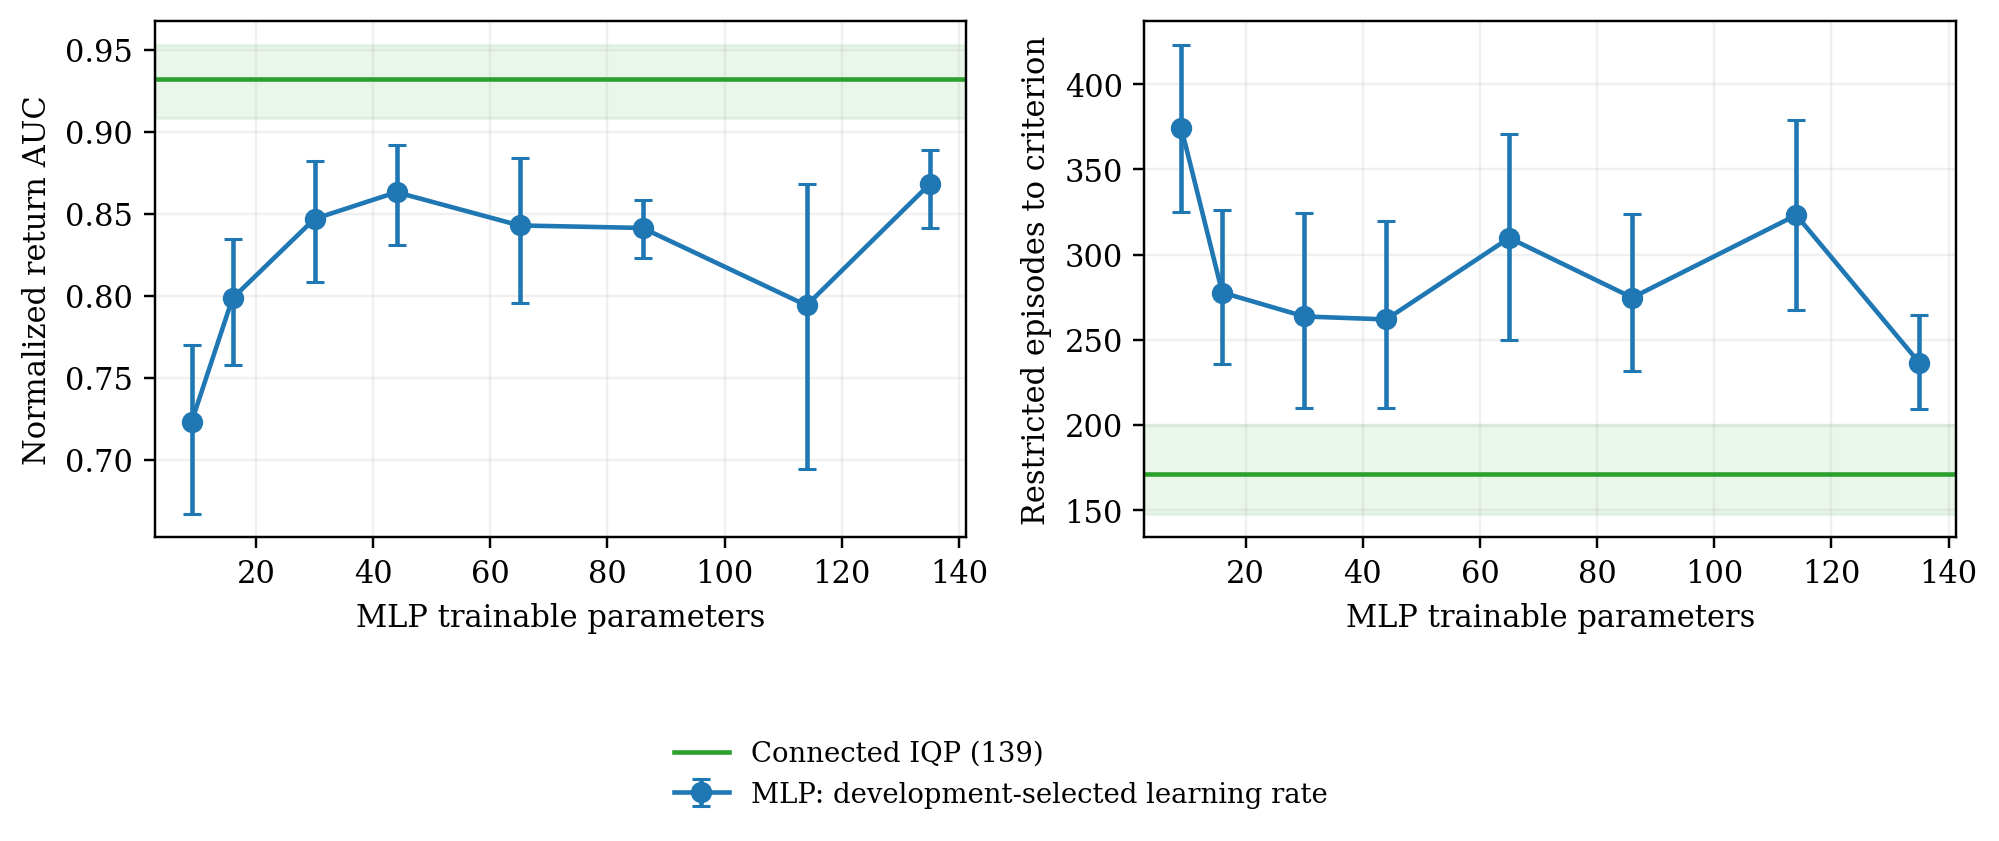

In [4]:
display(Image(filename=str(ROOT/'paper_assets/connected_iqp_mlp_size.png')))

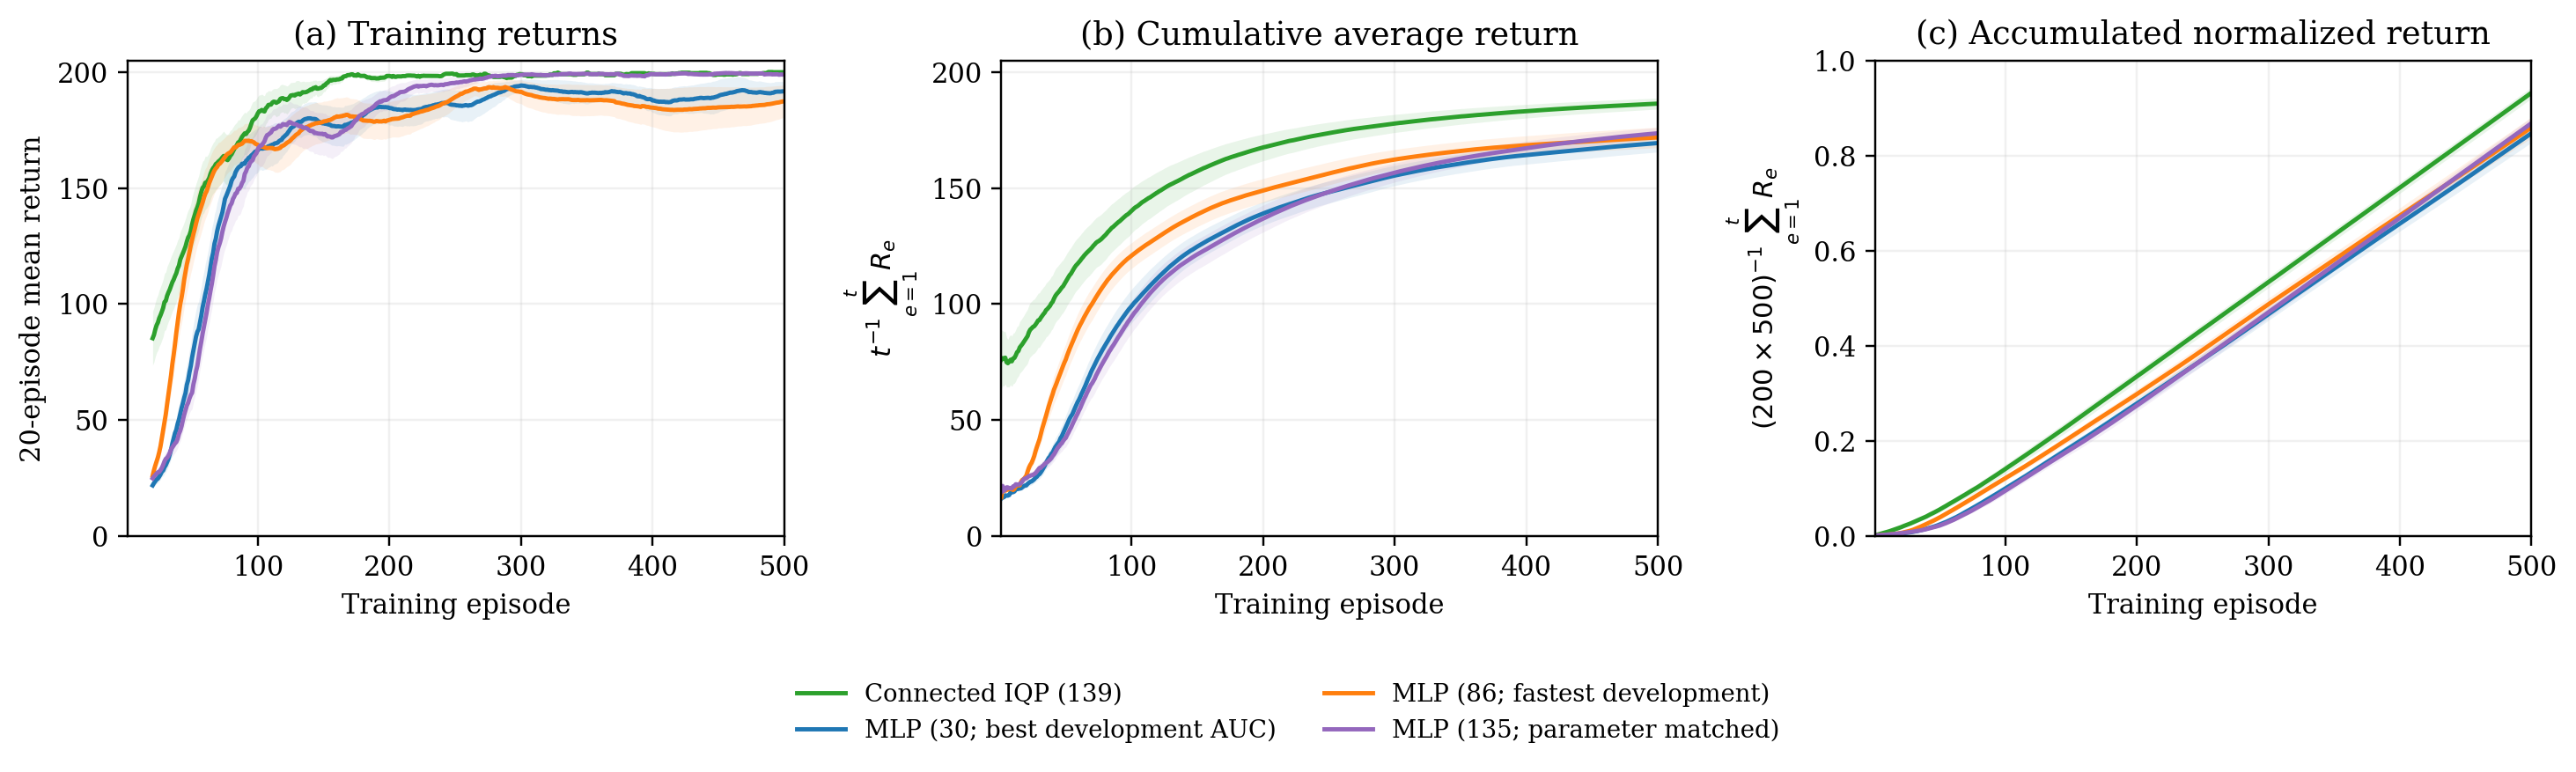

In [5]:
display(Image(filename=str(ROOT/'paper_assets/connected_iqp_training_curves.png')))

## Primary paired comparisons
Positive differences favor connected IQP, including fewer episodes to the criterion. Confidence intervals are ordinary paired-bootstrap intervals; p-values are Holm-adjusted over all selected MLP comparisons and both primary endpoints.

In [6]:
lines=['| MLP | AUC difference [95% CI] | Adjusted p | Episodes saved [95% CI] | Adjusted p |', '|---|---:|---:|---:|---:|']
for name,c in r['connected_minus_mlp'].items():
    a=c['auc'];t=c['solve_episode']
    lines.append(f"| {name} | {a['mean_difference']:.4f} [{a['ci95'][0]:.4f}, {a['ci95'][1]:.4f}] | {a['holm_p']:.4g} | {t['mean_difference']:.1f} [{t['ci95'][0]:.1f}, {t['ci95'][1]:.1f}] | {t['holm_p']:.4g} |")
display(Markdown('\n'.join(lines)))

| MLP | AUC difference [95% CI] | Adjusted p | Episodes saved [95% CI] | Adjusted p |
|---|---:|---:|---:|---:|
| mlp_h01_lr0p1 | 0.2090 [0.1514, 0.2741] | 3.433e-05 | 203.0 [150.7, 255.7] | 3.433e-05 |
| mlp_h02_lr0p1 | 0.1334 [0.0873, 0.1781] | 0.000721 | 106.2 [50.9, 160.9] | 0.01254 |
| mlp_h04_lr0p1 | 0.0850 [0.0502, 0.1198] | 0.002232 | 92.2 [44.7, 145.2] | 0.009853 |
| mlp_h06_lr0p1 | 0.0688 [0.0319, 0.1036] | 0.01254 | 90.5 [30.9, 149.4] | 0.02672 |
| mlp_h09_lr0p1 | 0.0891 [0.0360, 0.1451] | 0.01596 | 138.3 [65.5, 211.8] | 0.01254 |
| mlp_h12_lr0p03 | 0.0906 [0.0691, 0.1115] | 6.104e-05 | 103.2 [58.2, 152.0] | 0.002289 |
| mlp_h16_lr0p1 | 0.1378 [0.0602, 0.2455] | 0.002289 | 151.7 [96.6, 207.9] | 0.0003433 |
| mlp_h19_lr0p03 | 0.0639 [0.0343, 0.0978] | 0.00248 | 65.0 [31.6, 98.4] | 0.01254 |
| mlp_h12_lr0p1 | 0.0728 [0.0240, 0.1249] | 0.02672 | 90.2 [22.6, 161.1] | 0.02672 |

## Is there evidence of saturation?

In [7]:
r['saturation']

{'9': {'auc': {'mean_benefit_of_width19': 0.0251105,
   'ci98_3333': [-0.03519619999999998, 0.08913096250000002],
   'equivalence_margin': 0.02,
   'equivalence_established': False},
  'solve_episode': {'mean_benefit_of_width19': 73.25,
   'ci98_3333': [-5.8, 151.6],
   'equivalence_margin': 25,
   'equivalence_established': False},
  'equivalent_on_both': False},
 '12': {'auc': {'mean_benefit_of_width19': 0.026623000000000008,
   'ci98_3333': [-0.011617512500000008, 0.061913687500000016],
   'equivalence_margin': 0.02,
   'equivalence_established': False},
  'solve_episode': {'mean_benefit_of_width19': 38.2,
   'ci98_3333': [-35.1, 120.2],
   'equivalence_margin': 25,
   'equivalence_established': False},
  'equivalent_on_both': False},
 '16': {'auc': {'mean_benefit_of_width19': 0.07383700000000003,
   'ci98_3333': [-0.006271274999999963, 0.19813167500000012],
   'equivalence_margin': 0.02,
   'equivalence_established': False},
  'solve_episode': {'mean_benefit_of_width19': 86.65,
   

In [8]:
r['interblock_cut_purities']

{'initial': {'min': 0.5274987648173489,
  'max': 0.9999369596559546,
  'cut_count': 120,
  'cuts_with_purity_below_1_minus_1e_8': 120},
 'final': {'min': 0.5017273824244555,
  'max': 0.9999834610084709,
  'cut_count': 120,
  'cuts_with_purity_below_1_minus_1e_8': 120}}

## Complete development grid

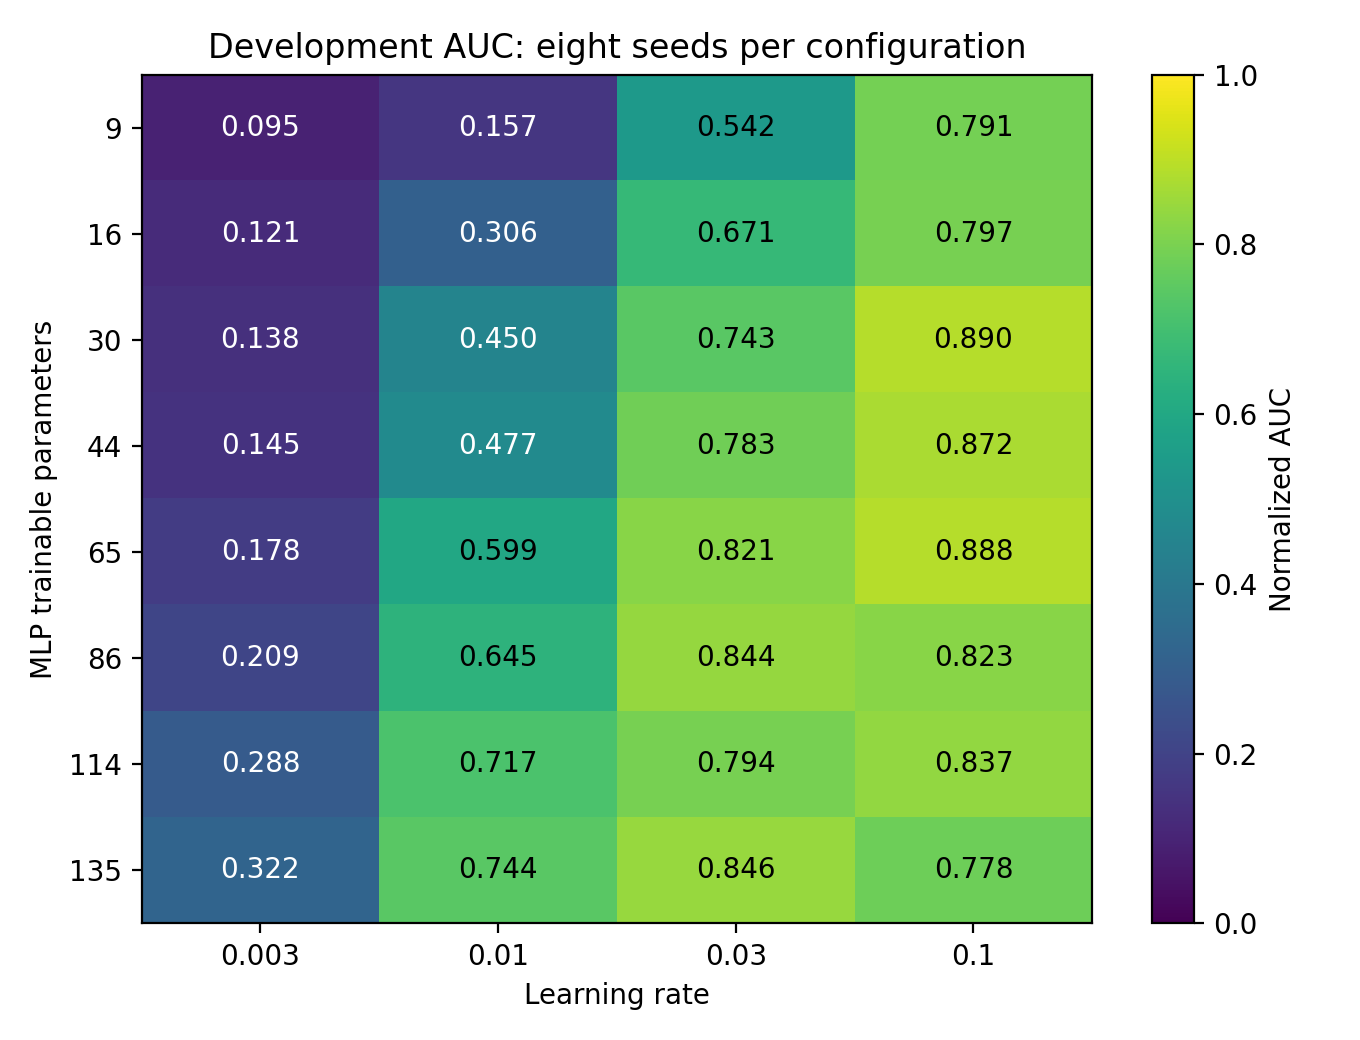

In [9]:
display(Image(filename=str(ROOT/'development_grid.png')))

In [10]:
r['selection']['development_means']

{'mlp_h01_lr0p003': {'auc': 0.09467125, 'solve': 501.0},
 'mlp_h01_lr0p01': {'auc': 0.15732500000000002, 'solve': 501.0},
 'mlp_h01_lr0p03': {'auc': 0.54229625, 'solve': 475.375},
 'mlp_h01_lr0p1': {'auc': 0.7910487500000001, 'solve': 303.0},
 'mlp_h02_lr0p003': {'auc': 0.12122625, 'solve': 501.0},
 'mlp_h02_lr0p01': {'auc': 0.30598000000000003, 'solve': 501.0},
 'mlp_h02_lr0p03': {'auc': 0.67058, 'solve': 418.25},
 'mlp_h02_lr0p1': {'auc': 0.79676375, 'solve': 332.5},
 'mlp_h04_lr0p003': {'auc': 0.13827250000000002, 'solve': 501.0},
 'mlp_h04_lr0p01': {'auc': 0.4497275, 'solve': 501.0},
 'mlp_h04_lr0p03': {'auc': 0.74321375, 'solve': 363.25},
 'mlp_h04_lr0p1': {'auc': 0.889785, 'solve': 232.375},
 'mlp_h06_lr0p003': {'auc': 0.14487125, 'solve': 501.0},
 'mlp_h06_lr0p01': {'auc': 0.47697375, 'solve': 501.0},
 'mlp_h06_lr0p03': {'auc': 0.7828350000000001, 'solve': 285.875},
 'mlp_h06_lr0p1': {'auc': 0.8715999999999999, 'solve': 233.75},
 'mlp_h09_lr0p003': {'auc': 0.17831375, 'solve': 5

## Numerical and training verification

In [11]:
json.loads((ROOT/'circuit_verification.json').read_text())

[{'qubits': 9,
  'parameters': 59,
  'max_probability_error': 7.452078890080038e-08,
  'first_block_reduced_purity': 0.9987260356930537,
  'predicted_first_cut_purity': 0.9987260356930581,
  'finite_difference_errors': {'weights': 6.465241312980652e-06,
   'bias': 6.6533684730529785e-06,
   'pair': 3.3229589462280273e-06,
   'triple': 2.806633710861206e-05,
   'bridge': 5.6791119277477264e-05},
  'zero_bridge_error': 2.9802322387695312e-08,
  'batch_gradient_error': 3.725290298461914e-08,
  'milliseconds_per_inference': 0.36889416980557144},
 {'qubits': 21,
  'parameters': 139,
  'max_probability_error': 7.083764036464046e-08,
  'first_block_reduced_purity': 0.9987260356930444,
  'predicted_first_cut_purity': 0.9987260356930581,
  'finite_difference_errors': {'weights': 8.538016118109226e-06,
   'bias': 2.6676803827285767e-05,
   'pair': 2.3527070879936218e-05,
   'triple': 9.700655937194824e-06,
   'bridge': 2.1230429410934448e-05},
  'zero_bridge_error': 2.9802322387695312e-08,
  'ba

In [12]:
json.loads((ROOT/'training_equivalence.json').read_text())

[{'model': 'iqp_connected',
  'same_trajectory': True,
  'max_parameter_error': 2.9802322387695312e-08},
 {'model': 'mlp_h19_lr0p1',
  'same_trajectory': True,
  'max_parameter_error': 2.9802322387695312e-08}]

## Reproduction

Use the `torchlane` environment and preserve the stage separation:

```bash
python connected_majority_iqp.py
python test_connected_study_trainer.py
python connected_iqp_mlp_study.py run --phase development --jobs 4
python connected_iqp_mlp_study.py lock
python connected_iqp_mlp_study.py run --phase test --jobs 4
python analyze_connected_iqp_study.py audit-initial --jobs 4
python analyze_connected_iqp_study.py analyze
```

Completed runs are reused, and a saved development-selection lock is not
overwritten. Raw per-episode returns, initial/final model checkpoints and
training logs are saved under the study results directory.